# Examining Sub-Research Question 1

The first sub-research question is as follows: **'Are there differences in content between the F/F and M/M fan fiction categories on Archive of Our Own?'**

In [2]:
# Import package
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10047515""","""Puppy Love""","""Established Relationship, Pets…","""No Archive Warnings Apply""","""M/M""","""Ray Palmer, Nate Heywood, Mart…",null,"""English""","""Teen And Up Audiences""","""Nate Heywood/Ray Palmer""","""by spiderscribe""","""1/1""","""""","""2017-03-04""","""5,179""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10104437""","""Goodnight""","""Cuddling & Snuggling, pure flu…","""No Archive Warnings Apply""","""M/M""",null,null,"""English""","""General Audiences""","""Ray Palmer/Mick Rory""","""by RazzleyD""","""1/1""","""""","""2017-03-05""","""611""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10128050""","""Underneath""","""Public Sex, Martin Stein (brie…","""Creator Chose Not To Use Archi…","""M/M""","""Nate Heywood, Ray Palmer""",null,"""English""","""Explicit""",null,"""by waveryder""","""1/1""","""""","""2017-03-09""","""2,074""","""DC's Legends of Tomorrow (TV)""",null,null,null,"""Nate Heywood/Ray Palmer, Steel…"
"""10194386""","""how do you sleep""","""Heavy Angst, Hurt/Comfort, Ang…","""No Archive Warnings Apply""","""M/M""","""Ray Palmer, Nate Heywood""",null,"""English""","""Teen And Up Audiences""",null,"""by orphan_account""","""2/5""","""""","""2017-03-09""","""1,945""","""DC's Legends of Tomorrow (TV)""",null,null,null,"""Nate Heywood/Ray Palmer, Nate …"


In [4]:
# Count the amount of fan works per fandom and category composition
ff_amt = df_metadata.filter(pl.col("Category") == "F/F").select(pl.len())
mm_amt = df_metadata.filter(pl.col("Category") == "M/M").select(pl.len())

print(f"""Femslash Fan Works Amount: {ff_amt}
Slash Fan Works Amount: {mm_amt}""")

Femslash Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 2028 │
└──────┘
Slash Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 3685 │
└──────┘


## 1. Ratings

### 1.1 Creating the Ratings Datasets

In [5]:
df_ratings_ff = df_metadata.filter(
    (pl.col("Category") == "F/F")
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Femslash Freq"}).with_columns((pl.col("Femslash Freq") / ff_amt.item(0,0) * 100).alias("Femslash %")) # Filtered by F/F

df_ratings_mm = df_metadata.filter(
    (pl.col("Category") == "M/M")
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Slash Freq"}).with_columns((pl.col("Slash Freq") / mm_amt.item(0,0) * 100).alias("Slash %")) # Filtered by M/M

print("Femslash Ratings Amount:")
df_ratings_ff.show(5)
print("Slash Ratings Amount:")
df_ratings_mm.show(5)

Femslash Ratings Amount:


Rating,Femslash Freq,Femslash %
str,u32,f64
"""Teen And Up Audiences""",687,33.87574
"""General Audiences""",645,31.804734
"""Mature""",242,11.932939
"""Not Rated""",231,11.390533
"""Explicit""",223,10.996055


Slash Ratings Amount:


Rating,Slash Freq,Slash %
str,u32,f64
"""Teen And Up Audiences""",1098,29.796472
"""Explicit""",952,25.834464
"""General Audiences""",717,19.457259
"""Mature""",597,16.200814
"""Not Rated""",321,8.710991


### 1.2 Visualizing the Ratings Datasets

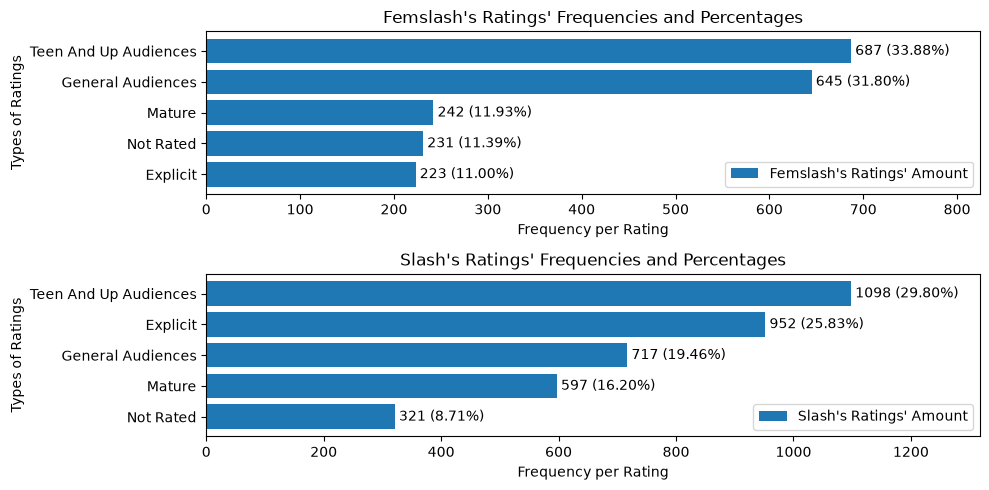

In [6]:
N = len(df_ratings_ff["Rating"]) # Amount of groups
width = 0.8 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(2, 1, figsize=(10, 5)) # Set figure size

# Plot a horizontal bar plot
p1 = ax[0].barh(ind, df_ratings_ff["Femslash Freq"], width, label="Femslash's Ratings' Amount")
p2 = ax[1].barh(ind, df_ratings_mm["Slash Freq"], width, label="Slash's Ratings' Amount")

# Combine the Frequencies and %
ff_labels = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_ff["Femslash Freq"],
        df_ratings_ff["Femslash %"]
    )
]

mm_labels = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_mm["Slash Freq"],
        df_ratings_mm["Slash %"]
    )
]

#labels
ax[0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0].set_xlabel('Frequency per Rating')
ax[0].set_title('Femslash\'s Ratings\' Frequencies and Percentages')
ax[0].set_ylabel('Types of Ratings')
ax[0].set_yticks(ind)
ax[0].set_yticklabels(df_ratings_ff['Rating'])
ax[0].legend(loc='best')

ax[1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1].set_xlabel('Frequency per Rating')
ax[1].set_title('Slash\'s Ratings\' Frequencies and Percentages')
ax[1].set_ylabel('Types of Ratings')
ax[1].set_yticks(ind)
ax[1].set_yticklabels(df_ratings_mm['Rating'])
ax[1].legend(loc='best')

ax[0].bar_label(p1, labels=ff_labels, padding=3)
ax[1].bar_label(p2, labels=mm_labels, padding=3)

# Add space for the labels
ax[0].set_xlim(right=df_ratings_ff["Femslash Freq"].max() * 1.20)
ax[1].set_xlim(right=df_ratings_mm["Slash Freq"].max() * 1.20)

plt.tight_layout()
plt.show()

## 2. Archive Warnings

### 2.1 Creating the Archive Warnings Datasets

In [7]:
df_aw_ff = df_metadata.filter(
    (pl.col("Category") == "F/F")
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Femslash Freq"}).with_columns((pl.col("Femslash Freq") / ff_amt.item(0,0) * 100).alias("Femslash %")) # Filtered by F/F

df_aw_mm = df_metadata.filter(
    (pl.col("Category") == "M/M")
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Slash Freq"}).with_columns((pl.col("Slash Freq") / mm_amt.item(0,0) * 100).alias("Slash %")) # Filtered by M/M

print("Femslash Archive Warnings Amount:")
df_aw_ff.show(6)
print("Slash Archive Warnings Amount:")
df_aw_mm.show(6)

Femslash Archive Warnings Amount:


Archive Warning,Femslash Freq,Femslash %
str,u32,f64
"""No Archive Warnings Apply""",1201,59.220907
"""Creator Chose Not To Use Archi…",658,32.445759
"""Graphic Depictions Of Violence""",53,2.613412
"""Major Character Death""",30,1.47929
"""Underage Sex""",15,0.739645
"""Rape/Non-Con""",8,0.394477


Slash Archive Warnings Amount:


Archive Warning,Slash Freq,Slash %
str,u32,f64
"""No Archive Warnings Apply""",1852,50.257802
"""Creator Chose Not To Use Archi…",1064,28.873813
"""Underage Sex""",253,6.865672
"""Graphic Depictions Of Violence""",115,3.12076
"""Major Character Death""",58,1.573948
"""Rape/Non-Con""",40,1.085482


### 2.2 Visualizing the Archive Warnings Datasets

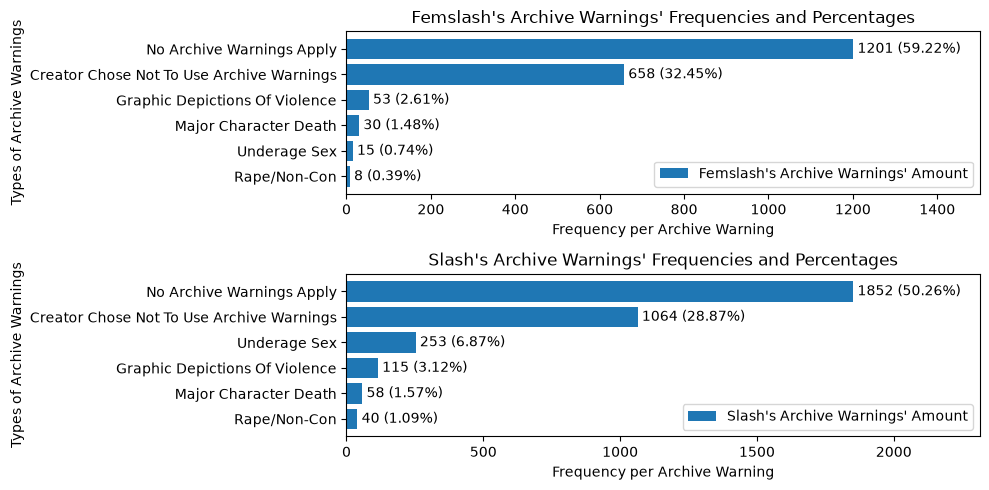

In [8]:
N = len(df_aw_ff["Archive Warning"]) # Amount of groups
width = 0.8 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(2, 1, figsize=(10, 5)) # Set figure size

# Plot a horizontal bar plot
p1 = ax[0].barh(ind, df_aw_ff["Femslash Freq"], width, label="Femslash's Archive Warnings' Amount")
p2 = ax[1].barh(ind, df_aw_mm["Slash Freq"], width, label="Slash's Archive Warnings' Amount")

# Combine the Frequencies and %
ff_labels = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_aw_ff["Femslash Freq"],
        df_aw_ff["Femslash %"]
    )
]

mm_labels = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_aw_mm["Slash Freq"],
        df_aw_mm["Slash %"]
    )
]

#labels
ax[0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0].set_xlabel('Frequency per Archive Warning')
ax[0].set_title('Femslash\'s Archive Warnings\' Frequencies and Percentages')
ax[0].set_ylabel('Types of Archive Warnings')
ax[0].set_yticks(ind)
ax[0].set_yticklabels(df_aw_ff['Archive Warning'])
ax[0].legend(loc='best')

ax[1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1].set_xlabel('Frequency per Archive Warning')
ax[1].set_title('Slash\'s Archive Warnings\' Frequencies and Percentages')
ax[1].set_ylabel('Types of Archive Warnings')
ax[1].set_yticks(ind)
ax[1].set_yticklabels(df_aw_mm['Archive Warning'])
ax[1].legend(loc='best')

ax[0].bar_label(p1, labels=ff_labels, padding=3)
ax[1].bar_label(p2, labels=mm_labels, padding=3)

# Add space for the labels
ax[0].set_xlim(right=df_aw_ff["Femslash Freq"].max() * 1.25)
ax[1].set_xlim(right=df_aw_mm["Slash Freq"].max() * 1.25)

plt.tight_layout()
plt.show()

## 3. Additional Tags

### 3.1 Creating the Additional Tags Datasets

In [9]:
# Read the CSV file
df_annotated_tags_fandom_category = pl.read_csv("./data/df_annotated_tags_fandom_category.csv")
df_add_tag_annotation = pl.read_csv("./data/df_additional_tag_annotations.csv")
df_annotated_tags_fandom_category.show()
df_add_tag_annotation.show()

Fandom,Category,Additional Tags,Freq,Character,Narrative,Porn,Kink
str,str,str,i64,str,str,str,str
"""Avatar: The Last Airbender (Ca…","""F/M""","""!!TW!!""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""""Has she always been good at t…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""""I love the smell of incest 😍😍…",1,"""No Character""","""No Narrative""","""Is Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""""I loved her to the point of i…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""DC's Legends of Tomorrow (TV)""","""F/F""","""""Mayday Mayday!""""",1,"""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""


Additional Tags,Character,Narrative,Porn,Kink
str,str,str,str,str
"""Fluff""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""
"""Angst""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""
"""AvaLance""","""No Character""","""Plot""","""Not Porn""","""Not Kink"""
"""Hurt/Comfort""","""Emotion/Mental State""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Angst with a Happy Ending""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""


In [10]:
def label_freq(df):
    """
    Calculates the frequency of the annotations.

    Parameter:
        df (DataFrame): Filtered DataFrame.
    Returns:
        df_label_freq (DataFrame): Contains the frequency of the annotations.
    """
    # Add the frequency of the annotations based on unique additional tags
    categories = ["Character", "Narrative", "Porn", "Kink"]

    df_unique_values = pl.DataFrame()
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[0]).value_counts()).unnest(categories[0]).rename({"Character": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[1]).value_counts()).unnest(categories[1]).rename({"Narrative": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[2]).value_counts()).unnest(categories[2]).rename({"Porn": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[3]).value_counts()).unnest(categories[3]).rename({"Kink": "Label"})])
    df_unique_values = df_unique_values.rename({"count": "Unique Additional Tags Frequency"})

    # Turn into lists
    char_list = ['No Character', 'Biography', 'Physical Feature', 'Emotion/Mental State', 'Relationship', "Personality"]
    nar_list = ['No Narrative', 'Plot', 'Event-related/Action', 'Theme/Genre', 'WorldSetting', 'Narrative Methods', 'Format']
    porn_list = ['Not Porn', 'Is Porn']
    kink_list = ['Not Kink', 'Is Kink']

    # Append the frequency of the annotations based on total additional tags
    df_freq_count = pl.DataFrame()
    for char_label in char_list:
        df_temp_char = pl.DataFrame({
            "Label": char_label,
            "Freq": df.filter(pl.col("Character") == char_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_char])
    for nar_label in nar_list:
        df_temp_nar = pl.DataFrame({
            "Label": nar_label,
            "Freq": df.filter(pl.col("Narrative") == nar_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_nar])
    for porn_label in porn_list:
        df_temp_porn = pl.DataFrame({
            "Label": porn_label,
            "Freq": df.filter(pl.col("Porn") == porn_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_porn])
    for kink_label in kink_list:
        df_temp_kink = pl.DataFrame({
            "Label": kink_label,
            "Freq": df.filter(pl.col("Kink") == kink_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_kink])
    
    df_freq_count = df_freq_count.rename({"Freq": "Total Additional Tags Frequency"})

    labels = df_freq_count.to_series(0)
    df_label_freq = pl.concat([df_unique_values, df_freq_count], how='align')
    df_label_freq = df_label_freq.sort(pl.col("Total Additional Tags Frequency"), descending=True)
    
    return df_label_freq

In [11]:
character_labels = ["No Character", "Biography", "Physical Feature", "Emotion/Mental State", "Relationship", "Personality"]
narrative_labels = ["No Narrative", "Plot", "Event-related/Action", "Theme/Genre", "WorldSetting", "Narrative Methods", "Format"]
porn_labels = ["Not Porn", "Is Porn"]
kink_labels = ["Not Kink", "Is Kink"]

In [14]:
# Filtered by F/F
df_add_tags_ff = df_annotated_tags_fandom_category.filter((pl.col("Category") == "F/F")).group_by("Additional Tags").agg(pl.col("Freq").sum())
df_add_tags_ff = df_add_tags_ff.join(df_add_tag_annotation, on="Additional Tags") # Add annotations
df_add_tags_ff = label_freq(df_add_tags_ff) # Calculate annotation frequencies
df_add_tags_ff = df_add_tags_ff.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
df_add_tags_ff = df_add_tags_ff.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category

# Filtered by M/M
df_add_tags_mm = df_annotated_tags_fandom_category.filter((pl.col("Category") == "F/M")).group_by("Additional Tags").agg(pl.col("Freq").sum())
df_add_tags_mm = df_add_tags_mm.join(df_add_tag_annotation, on="Additional Tags") # Add annotations
df_add_tags_mm = label_freq(df_add_tags_mm) # Calculate annotation frequencies
df_add_tags_mm = df_add_tags_mm.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
df_add_tags_mm = df_add_tags_mm.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category

print("Femslash Additional Tag Annotations' Amount:")
df_add_tags_ff.show(17)
print("Slash Additional Tag Annotations' Amount:")
df_add_tags_mm.show(17)

df_add_tags_ff = df_add_tags_ff.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)
df_add_tags_mm = df_add_tags_mm.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)

print("Femslash Additional Tag Annotations' Amount:")
df_add_tags_ff.show(17)
print("Slash Additional Tag Annotations' Amount:")
df_add_tags_mm.show(17)

Femslash Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""Not Kink""",5311,11389,"""Kink""",97.916667,97.927773
"""Not Porn""",5063,10625,"""Porn""",93.344395,91.358555
"""No Character""",3254,6210,"""Character""",59.992625,53.396389
"""No Narrative""",2776,4573,"""Narrative""",51.179941,39.320722
"""Event-related/Action""",975,2080,"""Narrative""",17.975664,17.884781
"""Relationship""",754,2048,"""Character""",13.90118,17.60963
"""Theme/Genre""",474,2002,"""Narrative""",8.738938,17.214101
"""Biography""",749,1747,"""Character""",13.808997,15.021496
"""Plot""",491,1386,"""Narrative""",9.05236,11.917455


Slash Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""Not Kink""",11857,33867,"""Kink""",97.588477,95.033252
"""Not Porn""",11173,30287,"""Porn""",91.958848,84.987513
"""No Character""",7454,19079,"""Character""",61.349794,53.537054
"""No Narrative""",6737,14163,"""Narrative""",55.44856,39.742403
"""Event-related/Action""",2190,8452,"""Narrative""",18.024691,23.716923
"""Relationship""",1654,6119,"""Character""",13.613169,17.170357
"""Is Porn""",977,5350,"""Porn""",8.041152,15.012487
"""Biography""",1694,4981,"""Character""",13.942387,13.977046
"""Theme/Genre""",844,4936,"""Narrative""",6.946502,13.850773


Femslash Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""No Character""",3254,6210,"""Character""",59.992625,53.396389
"""No Narrative""",2776,4573,"""Narrative""",51.179941,39.320722
"""Event-related/Action""",975,2080,"""Narrative""",17.975664,17.884781
"""Relationship""",754,2048,"""Character""",13.90118,17.60963
"""Theme/Genre""",474,2002,"""Narrative""",8.738938,17.214101
"""Biography""",749,1747,"""Character""",13.808997,15.021496
"""Plot""",491,1386,"""Narrative""",9.05236,11.917455
"""Emotion/Mental State""",499,1292,"""Character""",9.199853,11.1092
"""WorldSetting""",484,1054,"""Narrative""",8.923304,9.062769


Slash Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""No Character""",7454,19079,"""Character""",61.349794,53.537054
"""No Narrative""",6737,14163,"""Narrative""",55.44856,39.742403
"""Event-related/Action""",2190,8452,"""Narrative""",18.024691,23.716923
"""Relationship""",1654,6119,"""Character""",13.613169,17.170357
"""Is Porn""",977,5350,"""Porn""",8.041152,15.012487
"""Biography""",1694,4981,"""Character""",13.942387,13.977046
"""Theme/Genre""",844,4936,"""Narrative""",6.946502,13.850773
"""Emotion/Mental State""",1020,3890,"""Character""",8.395062,10.915621
"""Plot""",928,3543,"""Narrative""",7.63786,9.941914


### 3.2 Visualizing the Additional Tags Datasets

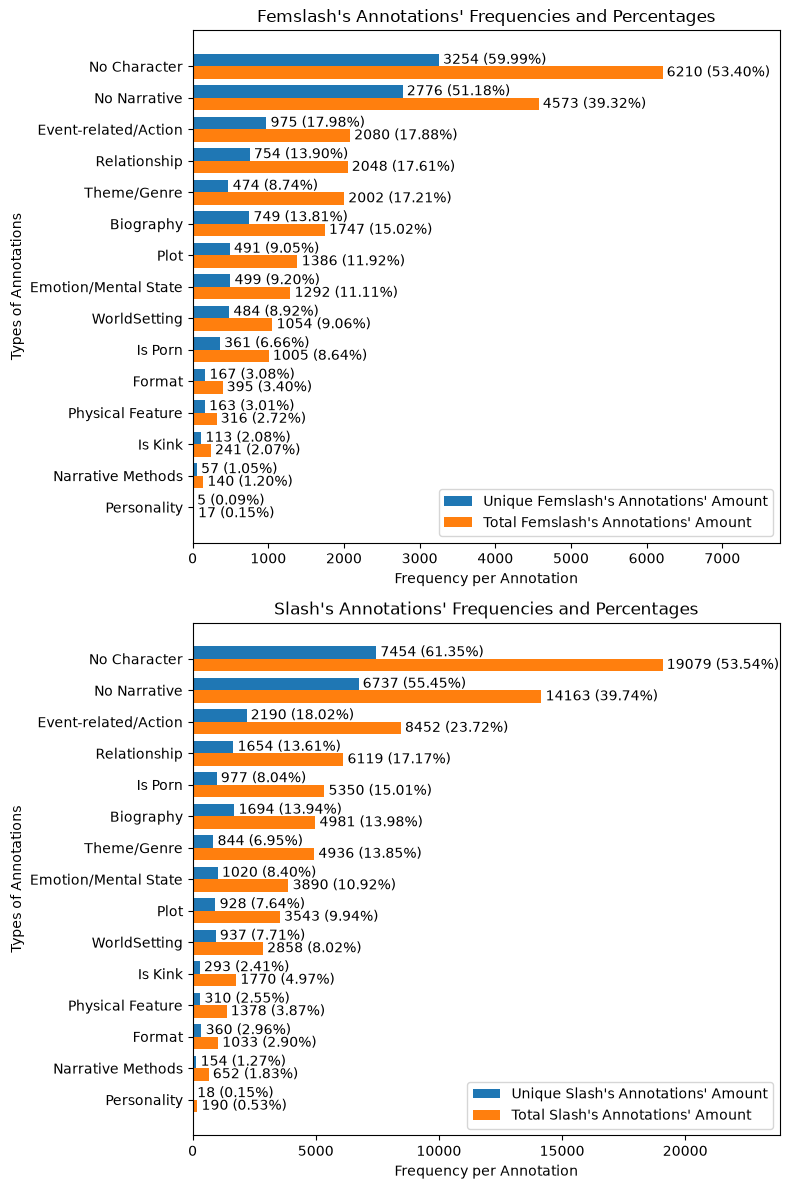

In [17]:
N = len(df_add_tags_ff["Label"]) # Amount of groups
width = 0.4 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(2, 1, figsize=(8, 12)) # Set figure size

# Femslash Additional Tags
# Plot a horizontal bar plot
p1 = ax[0].barh(ind, df_add_tags_ff["Unique Additional Tags Frequency"], width, label="Unique Femslash's Annotations' Amount")
p2 = ax[0].barh(ind + width, df_add_tags_ff["Total Additional Tags Frequency"], width, label="Total Femslash's Annotations' Amount")

# Combine the Frequencies and %
ff_labels_unique = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_ff["Unique Additional Tags Frequency"],
        df_add_tags_ff["Unique Additional Tags in %"]
    )
]

ff_labels_total = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_ff["Total Additional Tags Frequency"],
        df_add_tags_ff["Total Additional Tags in %"]
    )
]

#labels
ax[0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0].set_xlabel('Frequency per Annotation')
ax[0].set_title('Femslash\'s Annotations\' Frequencies and Percentages')
ax[0].set_ylabel('Types of Annotations')
ax[0].set_yticks(ind + width * 0.5)
ax[0].set_yticklabels(df_add_tags_ff['Label'])
ax[0].legend(loc='best')

ax[0].bar_label(p1, labels=ff_labels_unique, padding=3)
ax[0].bar_label(p2, labels=ff_labels_total, padding=3)

# Add space for the labels
ax[0].set_xlim(right=df_add_tags_ff["Total Additional Tags Frequency"].max() * 1.25)

# Slash Additional Tags
p1 = ax[1].barh(ind, df_add_tags_mm["Unique Additional Tags Frequency"], width, label="Unique Slash's Annotations' Amount")
p2 = ax[1].barh(ind + width, df_add_tags_mm["Total Additional Tags Frequency"], width, label="Total Slash's Annotations' Amount")

# Combine the Frequencies and %
mm_labels_unique = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_mm["Unique Additional Tags Frequency"],
        df_add_tags_mm["Unique Additional Tags in %"]
    )
]

mm_labels_total = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_mm["Total Additional Tags Frequency"],
        df_add_tags_mm["Total Additional Tags in %"]
    )
]

#labels
ax[1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1].set_xlabel('Frequency per Annotation')
ax[1].set_title('Slash\'s Annotations\' Frequencies and Percentages')
ax[1].set_ylabel('Types of Annotations')
ax[1].set_yticks(ind + width * 0.5)
ax[1].set_yticklabels(df_add_tags_mm['Label'])
ax[1].legend(loc='best')

ax[1].bar_label(p1, labels=mm_labels_unique, padding=3)
ax[1].bar_label(p2, labels=mm_labels_total, padding=3)

# Add space for the labels
ax[1].set_xlim(right=df_add_tags_mm["Total Additional Tags Frequency"].max() * 1.25)

plt.tight_layout()
plt.show()